<a href="https://colab.research.google.com/github/ANANDA-SWAROOP/sem-7-assignments/blob/main/pinn_cpu_thermal_heatmap_fixed_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CPU thermal maps: repaired ANN vs. heat-equation-informed PINN

This notebook compares two coordinate-conditioned temperature-field models on the **same held-out thermal-map frames** from the public commercial CPU thermal-map dataset:

- **ANN:** supervised temperature regression with uniform-pixel and hotspot-weighted losses.
- **PINN:** the same architecture, training samples, initialization and supervised losses, plus a heat-equation residual.

## What was wrong and what is fixed here

1. The failed run used a chronological split while its model inputs included normalized sample time. Validation/test then required time extrapolation. The default is now a **random split by whole frame**, for unseen-frame map estimation. `SPLIT_MODE = "chronological"` is available for a separate future-frame extrapolation experiment; it is harder and should not be mixed with map-interpolation results.
2. Uniform pixel sampling/loss let the models predict smooth average fields while missing localized hot regions. Hot-pixel samples are now drawn **within each frame's own top-temperature tail**, so a few globally hot frames cannot dominate.
3. The old PINN penalized an unmeasured source term toward zero, which encouraged suppressing heat. This version estimates the effective source from **training frames only**, then fits the PDE residual to that source target. High-magnitude source points are oversampled with a robust residual scale.
4. Workload/performance features change from one frame to the next. The temporal PDE term therefore uses a **nonuniform three-point finite difference of the predicted field along the observed frame/input trajectory**, including changes in workload features. Spatial second derivatives are computed by automatic differentiation. It does not incorrectly use only the partial derivative with workload features frozen.
5. ANN and PINN start from identical weights and use the same training batches. Best-checkpoint selection/early stopping monitors a validation objective that combines **uniform validation MSE and per-frame hotspot MSE**, rather than letting average MSE ignore hotspot quality.
6. Evaluation includes a train-mean baseline, point and full-map °C metrics, fixed-ground-truth-P95 hotspot precision/recall/IoU, top-5% localization IoU, peak temperature/location errors, and saved predictions/plots.

## Heat equation and the physical limits of this dataset

The transient heat equation is

\[
\frac{\partial T}{\partial t}=\alpha\left(\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}\right)+\frac{Q}{\rho c_p}.
\]

For standardized temperature \(u=(T-\mu_T)/\sigma_T\), normalized spatial coordinates, and normalized **sample-order** time \(\tau\), the implemented residual is

\[
r=D_\tau u-\alpha_{\mathrm{eff}}(u_{xx}+u_{yy})-s_{\mathrm{data}}(x,y,\tau).
\]

The effective source \(s_{\mathrm{data}}\) is estimated as \(D_\tau u_{\mathrm{observed}}-\alpha_{\mathrm{eff}}\nabla^2 u_{\mathrm{observed}}\) using training frames only. Since the dataset does not provide calibrated physical timestamps, pixel spacing, material coefficients, boundary conditions, or measured heat-source maps, `ALPHA_EFF` is a **dimensionless effective coefficient** and the inferred source is a data-derived forcing target. This is a data-informed PINN experiment, not a calibrated silicon simulator. The analytical derivative test checks derivative order/sign convention; it cannot replace missing physical calibration.

Dataset: [commercial_thermal_map_dataset](https://github.com/sheldonucr/commercial_thermal_map_dataset), Lu & Tan, MLCAD 2024, DOI: 10.1145/3670474.3685963.

In [ ]:
# 1. Environment, Google Drive persistence, and experiment settings
from pathlib import Path
import os, json, math, time, pickle, random, subprocess, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from google.colab import drive

drive.mount('/content/drive', force_remount=False)
PROJECT_DIR = Path('/content/drive/MyDrive/cpu_thermal_pinn_project')
DATA_ROOT = PROJECT_DIR / 'data' / 'raw'
RESULTS_DIR = PROJECT_DIR / 'results_v4'
FIGURES_DIR = RESULTS_DIR / 'figures'
METRICS_DIR = RESULTS_DIR / 'metrics'
CHECKPOINTS_DIR = RESULTS_DIR / 'checkpoints'
PREDICTIONS_DIR = RESULTS_DIR / 'predictions'
DATASET_REPO_DIR = DATA_ROOT / 'commercial_thermal_map_dataset'
for folder in [DATA_ROOT, FIGURES_DIR, METRICS_DIR, CHECKPOINTS_DIR, PREDICTIONS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATASET_REPO_URL = 'https://github.com/sheldonucr/commercial_thermal_map_dataset.git'
PICKLE_FILE_OVERRIDE = None  # Optional exact .pkl name, e.g. 'CPU_i5-3337U.pkl'
SPLIT_MODE = 'random'       # 'random' = map estimation; 'chronological' = future-frame extrapolation
SEED = 42

# Colab-friendly defaults. Start with these; increase point budgets/epochs after verifying outputs.
EPOCHS = 40
PATIENCE = 9
BATCH_SIZE = 512
MAX_TRAIN_POINTS = 20_000       # uniformly sampled training pixels
MAX_HOT_POINTS = 8_000          # additional points sampled from top-temperature tail of training frames
MAX_VAL_POINTS = 8_000
MAX_TEST_POINTS = 16_000
MAX_PDE_POINTS = 20_000
MAX_PDE_TAIL_POINTS = 8_000
PDE_BATCH_SIZE = 256
MAX_TEST_MAPS = 12
HIDDEN_WIDTH = 96
HIDDEN_DEPTH = 4
LEARNING_RATE = 5e-4
ALPHA_EFF = 1e-4                # effective coefficient on normalized x/y/tau coordinates; not measured silicon diffusivity
LAMBDA_PDE = 0.02               # PDE residual weight after source residual is standardized
PDE_TAIL_LOSS_WEIGHT = 0.5
HOTSPOT_LOSS_WEIGHT = 2.0       # emphasize per-frame hottest 15%; also used for validation checkpoint selection
HOTSPOT_QUANTILE = 85.0
FORCE_RETRAIN = False           # set True to restart ANN and PINN from scratch
RUN_VERSION = 'training_map_total_derivative_validation_hotspot_v4'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Project root (persistent): {PROJECT_DIR}')
print(f'Device: {DEVICE}; PyTorch: {torch.__version__}')
print(f'Split mode: {SPLIT_MODE}; field epochs: {EPOCHS}; physics collocation points/step: {PDE_BATCH_SIZE}')

# Keep the dataset under Drive. If GitHub is unavailable, the next cell allows a trusted .pkl upload.
existing_pkls = list(DATA_ROOT.rglob('*.pkl'))
if not existing_pkls:
    clone_target = DATASET_REPO_DIR
    if clone_target.exists() and not (clone_target / '.git').exists():
        clone_target = DATA_ROOT / 'commercial_thermal_map_dataset_repo'
    try:
        if (clone_target / '.git').exists():
            pull = subprocess.run(['git', '-C', str(clone_target), 'pull', '--ff-only'],
                                  capture_output=True, text=True, timeout=180)
            if pull.returncode != 0:
                print('Dataset update skipped:', pull.stderr[-500:])
        elif not clone_target.exists():
            clone = subprocess.run(['git', 'clone', '--depth', '1', DATASET_REPO_URL, str(clone_target)],
                                   capture_output=True, text=True, timeout=300)
            if clone.returncode != 0:
                print('Dataset clone did not complete; a manual upload fallback is available in the next cell.')
                print(clone.stderr[-1000:])
    except Exception as exc:
        print('Dataset repository fetch did not complete:', repr(exc))
print('Setup complete: models, metrics and figures are written to Drive.')

Mounted at /content/drive
Project root (persistent): /content/drive/MyDrive/cpu_thermal_pinn_project
Device: cuda; PyTorch: 2.11.0+cu130
Split mode: random; field epochs: 40; physics collocation points/step: 256
Setup complete: models, metrics and figures are written to Drive.


Available .pkl files:
  - commercial_thermal_map_dataset/data_files/CPU_R7_4800U.pkl (35.87 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i5_7zip.pkl (22.48 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i5_aobench.pkl (22.48 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i5_flac.pkl (22.48 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i5_opencv.pkl (22.48 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i5_stream.pkl (22.48 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i7_aio-stress.pkl (21.80 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i7_aobench.pkl (21.80 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i7_build-gcc.pkl (21.80 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i7_cachebench.pkl (21.80 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i7_compress-7zip.pkl (21.80 MiB)
  - commercial_thermal_map_dataset/data_files/CPU_i7_cyclictest.pkl (21.80 MiB)
  - commercial_thermal_map_dataset/data_files/C

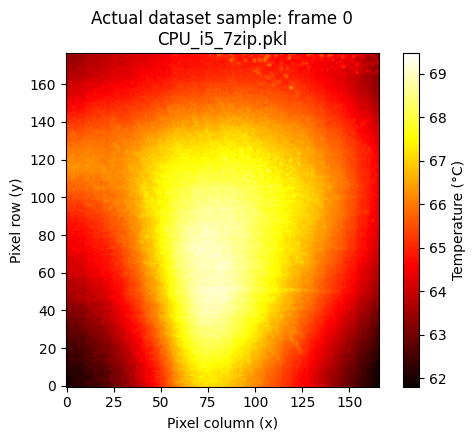

In [ ]:
# 2. Load the actual dataset and inspect what it contains
def is_git_lfs_pointer(path):
    """Git LFS pointer stubs are text, not usable pickled datasets."""
    try:
        with open(path, 'rb') as f:
            header = f.read(200)
        return header.startswith(b'version https://git-lfs.github.com/spec/v1')
    except OSError:
        return False

pkl_files = sorted(p for p in DATA_ROOT.rglob('*.pkl') if not is_git_lfs_pointer(p))
lfs_pointer_files = sorted(p for p in DATA_ROOT.rglob('*.pkl') if is_git_lfs_pointer(p))
if lfs_pointer_files:
    print('Skipped Git LFS pointer stubs (not actual pickle data):', [p.name for p in lfs_pointer_files[:10]])
if PICKLE_FILE_OVERRIDE:
    matches = [p for p in pkl_files if p.name == PICKLE_FILE_OVERRIDE]
    if not matches:
        raise FileNotFoundError(f'{PICKLE_FILE_OVERRIDE!r} not found under {DATA_ROOT}. Available files: {[p.name for p in pkl_files]}')
    DATASET_PATH = matches[0]
else:
    # Prefer transient CPU recordings if present; they are the most relevant for a time-dependent heat equation.
    preference_tokens = ['CPU_i5', 'CPU_i7', 'CPU_R7_4800U', 'GPU_RTX_4060']
    DATASET_PATH = None
    for token in preference_tokens:
        matches = [p for p in pkl_files if token.lower() in p.name.lower()]
        if matches:
            DATASET_PATH = matches[0]
            break
    if DATASET_PATH is None and pkl_files:
        DATASET_PATH = pkl_files[0]

if DATASET_PATH is None:
    print('No .pkl found in Drive. Upload a trusted pickle from the public dataset repository.')
    from google.colab import files
    uploaded = files.upload()
    upload_dir = DATA_ROOT / 'uploaded'
    upload_dir.mkdir(parents=True, exist_ok=True)
    for name, content in uploaded.items():
        if name.lower().endswith('.pkl'):
            (upload_dir / Path(name).name).write_bytes(content)
    pkl_files = sorted(p for p in DATA_ROOT.rglob('*.pkl') if not is_git_lfs_pointer(p))
    if PICKLE_FILE_OVERRIDE:
        pkl_files = [p for p in pkl_files if p.name == PICKLE_FILE_OVERRIDE]
    if not pkl_files:
        raise FileNotFoundError('No .pkl available. Verify the dataset clone or upload a trusted .pkl file.')
    DATASET_PATH = pkl_files[0]

print('Available .pkl files:')
for path in pkl_files:
    print(f'  - {path.relative_to(DATA_ROOT)} ({path.stat().st_size / (1024**2):.2f} MiB)')
print(f'\nSelected dataset: {DATASET_PATH}')
# Only load pickle files from a source you trust; pickle deserialization can execute code.
try:
    with open(DATASET_PATH, 'rb') as f:
        dataset_bundle = pickle.load(f)
except Exception as exc:
    raise RuntimeError(f'Could not load {DATASET_PATH.name}. If the repository supplied an incomplete file or Git LFS pointer, upload the actual trusted dataset .pkl into {DATA_ROOT}/uploaded and set PICKLE_FILE_OVERRIDE to its filename.') from exc
if not isinstance(dataset_bundle, dict) or 'input' not in dataset_bundle or 'output' not in dataset_bundle:
    raise ValueError("Expected pickle dictionary with keys 'input' and 'output'.")
raw_inputs = np.asarray(dataset_bundle['input'], dtype=np.float32)
raw_maps = np.asarray(dataset_bundle['output'], dtype=np.float32)
if raw_maps.ndim == 4 and raw_maps.shape[-1] == 1:
    raw_maps = raw_maps[..., 0]
elif raw_maps.ndim == 4 and raw_maps.shape[1] == 1:
    raw_maps = raw_maps[:, 0, ...]
if raw_maps.ndim != 3:
    raise ValueError(f'Expected maps with shape (N,H,W), got {raw_maps.shape}.')
if raw_inputs.shape[0] != raw_maps.shape[0]:
    raise ValueError(f'Input/output sample count mismatch: {raw_inputs.shape[0]} vs {raw_maps.shape[0]}.')
if raw_inputs.ndim < 2:
    raw_inputs = raw_inputs.reshape(len(raw_inputs), 1)
N_FRAMES, HEIGHT, WIDTH = raw_maps.shape
if N_FRAMES < 10:
    raise ValueError(f'Only {N_FRAMES} maps available. At least 10 frames are recommended for train/validation/test and source estimation.')
input_features_raw = raw_inputs.reshape(N_FRAMES, -1).astype(np.float32)
finite_temps = raw_maps[np.isfinite(raw_maps)]
if not finite_temps.size:
    raise ValueError('No finite temperature values found.')
print('\nDataset schema:')
print('  original input shape:', raw_inputs.shape)
print('  flattened input features per map:', input_features_raw.shape[1])
print('  temperature maps (N,H,W):', raw_maps.shape)
print(f'  finite temperature range: {finite_temps.min():.3f} to {finite_temps.max():.3f} °C')
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(raw_maps[0], origin='lower', cmap='hot')
fig.colorbar(im, ax=ax, label='Temperature (°C)')
ax.set_title(f'Actual dataset sample: frame 0\n{DATASET_PATH.name}')
ax.set_xlabel('Pixel column (x)'); ax.set_ylabel('Pixel row (y)')
fig.tight_layout(); plt.show()

In [ ]:
# 3. Split by whole frame, fit scalers on training frames only, and prepare shared training samples
if SPLIT_MODE not in {'random', 'chronological'}:
    raise ValueError("SPLIT_MODE must be 'random' or 'chronological'.")
rng_split = np.random.default_rng(SEED)
all_frame_ids = np.arange(N_FRAMES, dtype=np.int64)
n_train = max(1, int(round(0.70 * N_FRAMES)))
n_val = max(1, int(round(0.15 * N_FRAMES)))
if n_train + n_val >= N_FRAMES:
    n_train, n_val = N_FRAMES - 2, 1
if SPLIT_MODE == 'random':
    permuted = rng_split.permutation(all_frame_ids)
    train_frame_ids = np.sort(permuted[:n_train])
    val_frame_ids = np.sort(permuted[n_train:n_train+n_val])
    test_frame_ids = np.sort(permuted[n_train+n_val:])
else:
    train_frame_ids = all_frame_ids[:n_train]
    val_frame_ids = all_frame_ids[n_train:n_train+n_val]
    test_frame_ids = all_frame_ids[n_train+n_val:]
assert len(set(train_frame_ids) & set(val_frame_ids)) == 0
assert len(set(train_frame_ids) & set(test_frame_ids)) == 0
assert len(set(val_frame_ids) & set(test_frame_ids)) == 0

time_coord = np.linspace(0.0, 1.0, N_FRAMES, dtype=np.float32)  # normalized sample order; not seconds
feature_train = input_features_raw[train_frame_ids]
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    feature_mean = np.nanmean(feature_train, axis=0)
    feature_std = np.nanstd(feature_train, axis=0)
feature_mean = np.where(np.isfinite(feature_mean), feature_mean, 0.0).astype(np.float32)
feature_std = np.where(np.isfinite(feature_std) & (feature_std > 1e-8), feature_std, 1.0).astype(np.float32)
features_filled = np.where(np.isfinite(input_features_raw), input_features_raw, feature_mean[None, :]).astype(np.float32)
features_scaled = ((features_filled - feature_mean[None, :]) / feature_std[None, :]).astype(np.float32)
train_temp_values = raw_maps[train_frame_ids]
train_temp_values = train_temp_values[np.isfinite(train_temp_values)]
if train_temp_values.size == 0:
    raise ValueError('Training split contains no finite temperature values.')
TEMP_MEAN = float(train_temp_values.mean())
TEMP_STD = float(train_temp_values.std())
if not np.isfinite(TEMP_STD) or TEMP_STD < 1e-6:
    TEMP_STD = 1.0
HOT_THRESHOLD_TRAIN_C = float(np.percentile(train_temp_values, HOTSPOT_QUANTILE))
FEATURE_DIM = int(features_scaled.shape[1])
INPUT_DIM = 3 + FEATURE_DIM

# A signature change deliberately invalidates checkpoints from the failed v1 objective.
EXPERIMENT_SIGNATURE = {
    'run_version': RUN_VERSION,
    'dataset_file': str(DATASET_PATH.relative_to(DATA_ROOT)),
    'dataset_size_bytes': int(DATASET_PATH.stat().st_size),
    'map_shape': [int(N_FRAMES), int(HEIGHT), int(WIDTH)],
    'feature_dim': FEATURE_DIM, 'split_mode': SPLIT_MODE, 'seed': SEED,
    'max_train_points': MAX_TRAIN_POINTS, 'max_hot_points': MAX_HOT_POINTS,
    'batch_size': BATCH_SIZE, 'hidden_width': HIDDEN_WIDTH, 'hidden_depth': HIDDEN_DEPTH,
    'learning_rate': LEARNING_RATE,
    'alpha_eff': ALPHA_EFF, 'lambda_pde': LAMBDA_PDE,
    'hotspot_loss_weight': HOTSPOT_LOSS_WEIGHT, 'hotspot_quantile': HOTSPOT_QUANTILE,
    'max_val_points': MAX_VAL_POINTS, 'max_pde_points': MAX_PDE_POINTS,
    'max_pde_tail_points': MAX_PDE_TAIL_POINTS, 'pde_batch_size': PDE_BATCH_SIZE,
    'pde_tail_loss_weight': PDE_TAIL_LOSS_WEIGHT,
}

def make_model_inputs(frames, rows, cols):
    x = cols.astype(np.float32) / max(WIDTH - 1, 1)
    y = rows.astype(np.float32) / max(HEIGHT - 1, 1)
    tau = time_coord[frames]
    return np.column_stack([x, y, tau, features_scaled[frames]]).astype(np.float32)

def sample_map_points(target_map, frame_ids, count, seed, threshold=None, standardize_temp=True):
    """Sample finite (frame,row,col) points; optional threshold samples only the high-temperature tail."""
    frame_ids = np.asarray(frame_ids, dtype=np.int64)
    if count <= 0 or len(frame_ids) == 0:
        raise ValueError('Cannot sample points with count <= 0 or an empty frame list.')
    rng = np.random.default_rng(seed)
    frames_out, rows_out, cols_out, values_out = [], [], [], []
    obtained = 0
    attempts = 0
    while obtained < count and attempts < 300:
        draw_n = max(512, int((count - obtained) * (1.5 if threshold is None else 7.0)))
        f = rng.choice(frame_ids, size=draw_n, replace=True)
        r = rng.integers(0, HEIGHT, size=draw_n)
        c = rng.integers(0, WIDTH, size=draw_n)
        v = target_map[f, r, c]
        good = np.isfinite(v)
        if threshold is not None:
            good &= v >= threshold
        if np.any(good):
            f, r, c, v = f[good], r[good], c[good], v[good]
            take = min(count - obtained, len(v))
            frames_out.append(f[:take]); rows_out.append(r[:take]); cols_out.append(c[:take]); values_out.append(v[:take])
            obtained += take
        attempts += 1
    if obtained < count:
        raise RuntimeError(f'Only sampled {obtained}/{count} points. The requested threshold may be too high or the selected maps contain too few finite values.')
    f = np.concatenate(frames_out); r = np.concatenate(rows_out); c = np.concatenate(cols_out); v = np.concatenate(values_out)
    X = make_model_inputs(f, r, c)
    if standardize_temp:
        y = ((v - TEMP_MEAN) / TEMP_STD).astype(np.float32).reshape(-1, 1)
    else:
        y = v.astype(np.float32).reshape(-1, 1)
    finite = np.isfinite(X).all(axis=1) & np.isfinite(y[:, 0])
    return X[finite], y[finite], f[finite], r[finite], c[finite]

def top_quantile_target_map(target_map, frame_ids, quantile):
    """Keep only each selected frame's own top-temperature quantile; all other pixels become NaN."""
    masked = np.full(target_map.shape, np.nan, dtype=np.float32)
    for frame in np.asarray(frame_ids, dtype=np.int64):
        values = target_map[int(frame)]
        finite_values = values[np.isfinite(values)]
        if finite_values.size == 0:
            continue
        threshold = float(np.percentile(finite_values, quantile))
        keep = np.isfinite(values) & (values >= threshold)
        masked[int(frame)] = np.where(keep, values, np.nan)
    return masked

train_hot_target_map = top_quantile_target_map(raw_maps, train_frame_ids, HOTSPOT_QUANTILE)
val_hot_target_map = top_quantile_target_map(raw_maps, val_frame_ids, HOTSPOT_QUANTILE)
train_X, train_y, *_ = sample_map_points(raw_maps, train_frame_ids, MAX_TRAIN_POINTS, SEED+1)
hot_X, hot_y, *_ = sample_map_points(train_hot_target_map, train_frame_ids, MAX_HOT_POINTS, SEED+2)
val_X, val_y, *_ = sample_map_points(raw_maps, val_frame_ids, MAX_VAL_POINTS, SEED+3)
val_hot_X, val_hot_y, *_ = sample_map_points(val_hot_target_map, val_frame_ids, MAX_HOT_POINTS, SEED+33)
test_X, test_y, *_ = sample_map_points(raw_maps, test_frame_ids, MAX_TEST_POINTS, SEED+4)
train_loader = DataLoader(TensorDataset(torch.from_numpy(train_X), torch.from_numpy(train_y)),
                          batch_size=BATCH_SIZE, shuffle=True, drop_last=False,
                          generator=torch.Generator().manual_seed(SEED), num_workers=0)
hot_loader = DataLoader(TensorDataset(torch.from_numpy(hot_X), torch.from_numpy(hot_y)),
                        batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED+1), num_workers=0)
val_loader = DataLoader(TensorDataset(torch.from_numpy(val_X), torch.from_numpy(val_y)),
                        batch_size=2048, shuffle=False, num_workers=0)
val_hot_loader = DataLoader(TensorDataset(torch.from_numpy(val_hot_X), torch.from_numpy(val_hot_y)),
                            batch_size=2048, shuffle=False, num_workers=0)

print('Split summary (whole frames are kept together):')
print(f'  frames train/validation/test: {len(train_frame_ids)}/{len(val_frame_ids)}/{len(test_frame_ids)}')
print(f'  points uniform train / per-frame hot train / uniform validation / hot validation / test: {len(train_X):,} / {len(hot_X):,} / {len(val_X):,} / {len(val_hot_X):,} / {len(test_X):,}')
print(f'  train-only temperature scaler: mean={TEMP_MEAN:.3f} °C, std={TEMP_STD:.3f} °C')
print(f'  global train P{HOTSPOT_QUANTILE:.0f} reference threshold: {HOT_THRESHOLD_TRAIN_C:.3f} °C')
print("  hotspot sampling uses each frame's own top-quantile pixels for balanced coverage")
print(f'  validation frames: {val_frame_ids.tolist()[:20]}'); print(f'  test frames: {test_frame_ids.tolist()[:20]}')
print('NOTE: random split is for unseen-frame map estimation, not forecasting future time steps.')

Split summary (whole frames are kept together):
  frames train/validation/test: 70/15/15
  points uniform train / per-frame hot train / uniform validation / hot validation / test: 20,000 / 8,000 / 8,000 / 8,000 / 16,000
  train-only temperature scaler: mean=72.469 °C, std=5.912 °C
  global train P85 reference threshold: 79.604 °C
  hotspot sampling uses each frame's own top-quantile pixels for balanced coverage
  validation frames: [6, 11, 30, 34, 44, 49, 54, 58, 67, 74, 82, 85, 88, 90, 98]
  test frames: [8, 12, 13, 14, 19, 22, 35, 36, 41, 47, 53, 64, 65, 66, 77]
NOTE: random split is for unseen-frame map estimation, not forecasting future time steps.


In [ ]:
# 4. Derive a training-only source map from the transient heat equation and test derivatives
# u is standardized temperature; tau, x, and y are normalized coordinates. The source is estimated
# ONLY from frames in the provided frame_ids. The same helper is later used on test maps for a
# post-training diagnostic, never for fitting.
u_maps = ((raw_maps - TEMP_MEAN) / TEMP_STD).astype(np.float32)
dx = 1.0 / max(WIDTH - 1, 1)
dy = 1.0 / max(HEIGHT - 1, 1)

def estimate_heat_source_map(frame_ids):
    frame_ids = np.sort(np.asarray(frame_ids, dtype=np.int64))
    q_map = np.full((N_FRAMES, HEIGHT, WIDTH), np.nan, dtype=np.float32)
    if len(frame_ids) < 3:
        return q_map, np.empty(0, dtype=np.int64)
    valid_center_frames = []
    for j in range(1, len(frame_ids)-1):
        ip, ic, inext = int(frame_ids[j-1]), int(frame_ids[j]), int(frame_ids[j+1])
        t_prev, t_cur, t_next = float(time_coord[ip]), float(time_coord[ic]), float(time_coord[inext])
        h1, h2 = t_cur - t_prev, t_next - t_cur
        if h1 <= 0 or h2 <= 0:
            continue
        # Three-point finite-difference formula for a nonuniform stencil in sample-order tau.
        a_prev = -h2 / (h1 * (h1 + h2))
        a_cur = (h2 - h1) / (h1 * h2)
        a_next = h1 / (h2 * (h1 + h2))
        ut = a_prev*u_maps[ip] + a_cur*u_maps[ic] + a_next*u_maps[inext]
        center = u_maps[ic, 1:-1, 1:-1]
        lap_y = (u_maps[ic, 2:, 1:-1] - 2.0*center + u_maps[ic, :-2, 1:-1]) / (dy*dy)
        lap_x = (u_maps[ic, 1:-1, 2:] - 2.0*center + u_maps[ic, 1:-1, :-2]) / (dx*dx)
        q = ut[1:-1, 1:-1] - ALPHA_EFF*(lap_x + lap_y)
        valid = np.isfinite(q) & np.isfinite(ut[1:-1, 1:-1]) & np.isfinite(center)
        valid &= np.isfinite(u_maps[ip, 1:-1, 1:-1]) & np.isfinite(u_maps[inext, 1:-1, 1:-1])
        valid &= np.isfinite(u_maps[ic, 2:, 1:-1]) & np.isfinite(u_maps[ic, :-2, 1:-1])
        valid &= np.isfinite(u_maps[ic, 1:-1, 2:]) & np.isfinite(u_maps[ic, 1:-1, :-2])
        patch = np.full_like(q, np.nan, dtype=np.float32)
        patch[valid] = q[valid].astype(np.float32)
        q_map[ic, 1:-1, 1:-1] = patch
        valid_center_frames.append(ic)
    return q_map, np.asarray(valid_center_frames, dtype=np.int64)

source_target_map, source_frame_ids = estimate_heat_source_map(train_frame_ids)

def build_neighbor_lookup(frame_ids):
    """Return prev/next frame IDs matching the same stencil used by source estimation."""
    frames = np.sort(np.asarray(frame_ids, dtype=np.int64))
    return {int(frames[j]): (int(frames[j-1]), int(frames[j+1])) for j in range(1, len(frames)-1)}

train_neighbor_lookup = build_neighbor_lookup(train_frame_ids)

def neighbor_conditioned_inputs(frame_ids, rows, cols, neighbor_lookup):
    """Build current/previous/next model inputs and nonuniform time steps at the same pixels."""
    frames = np.asarray(frame_ids, dtype=np.int64)
    rows = np.asarray(rows, dtype=np.int64)
    cols = np.asarray(cols, dtype=np.int64)
    prev_frames = np.asarray([neighbor_lookup[int(f)][0] for f in frames], dtype=np.int64)
    next_frames = np.asarray([neighbor_lookup[int(f)][1] for f in frames], dtype=np.int64)
    current_X = make_model_inputs(frames, rows, cols)
    previous_X = make_model_inputs(prev_frames, rows, cols)
    next_X = make_model_inputs(next_frames, rows, cols)
    h1 = (time_coord[frames] - time_coord[prev_frames]).astype(np.float32).reshape(-1, 1)
    h2 = (time_coord[next_frames] - time_coord[frames]).astype(np.float32).reshape(-1, 1)
    if np.any(h1 <= 0) or np.any(h2 <= 0):
        raise ValueError('Non-positive time interval in finite-difference collocation batch.')
    return current_X, previous_X, next_X, h1, h2

source_values = source_target_map[source_frame_ids]
source_values = source_values[np.isfinite(source_values)]
if len(source_frame_ids) < 3 or source_values.size < 100:
    raise ValueError('Too few finite training-only source targets. Select a dataset with a longer continuous recording.')
# Robust scale: source targets have sparse large values where thermal gradients are sharp.
Q_CENTER = float(np.median(source_values))
Q_SCALE = float(1.4826*np.median(np.abs(source_values - Q_CENTER)))
if not np.isfinite(Q_SCALE) or Q_SCALE < 1e-6:
    Q_SCALE = float(np.std(source_values))
if not np.isfinite(Q_SCALE) or Q_SCALE < 1e-6:
    Q_SCALE = 1.0
SOURCE_TAIL_THRESHOLD = float(np.percentile(np.abs(source_values), HOTSPOT_QUANTILE))
print(f'Training-only source targets: {len(source_frame_ids)} frames; {source_values.size:,} valid pixels')
print(f'Source robust center/scale: {Q_CENTER:.4g} / {Q_SCALE:.4g}; high-|source| threshold P{HOTSPOT_QUANTILE:.0f}: {SOURCE_TAIL_THRESHOLD:.4g}')

# Build a fixed pool of physics collocation points. Both sets come exclusively from the training source map.
pde_uniform_X, pde_uniform_q, pde_uniform_f, pde_uniform_r, pde_uniform_c = sample_map_points(
    source_target_map, source_frame_ids, MAX_PDE_POINTS, SEED+50, standardize_temp=False)
pde_tail_X, _, pde_tail_f, pde_tail_r, pde_tail_c = sample_map_points(
    np.abs(source_target_map).astype(np.float32), source_frame_ids, MAX_PDE_TAIL_POINTS,
    SEED+51, threshold=SOURCE_TAIL_THRESHOLD, standardize_temp=False)
pde_tail_q = source_target_map[pde_tail_f, pde_tail_r, pde_tail_c].astype(np.float32).reshape(-1, 1)
pde_uniform_q = pde_uniform_q.astype(np.float32).reshape(-1, 1)
print(f'Physics samples: uniform={len(pde_uniform_X):,}, high-|source|={len(pde_tail_X):,}; labels are derived only from train frames.')

# Fourier coordinate embedding helps represent localized hotspots. Derivatives are still taken w.r.t. raw x,y,tau.
FOURIER_FREQUENCIES = (1, 2, 4, 8, 16)
def encode_inputs(inputs):
    x, y = inputs[:, 0:1], inputs[:, 1:2]
    parts = [inputs[:, 0:3]]
    for freq in FOURIER_FREQUENCIES:
        parts.extend([torch.sin(2*math.pi*freq*x), torch.cos(2*math.pi*freq*x),
                      torch.sin(2*math.pi*freq*y), torch.cos(2*math.pi*freq*y)])
    parts.append(inputs[:, 3:])
    return torch.cat(parts, dim=1)

def make_mlp(input_dim, output_dim=1, width=HIDDEN_WIDTH, depth=HIDDEN_DEPTH):
    layers=[]; in_dim=input_dim
    for _ in range(depth):
        layers.extend([nn.Linear(in_dim,width), nn.Tanh()]); in_dim=width
    layers.append(nn.Linear(in_dim,output_dim))
    return nn.Sequential(*layers)

class ThermalField(nn.Module):
    """Same coordinate-conditioned temperature network for ANN and PINN."""
    def __init__(self, feature_dim, width=HIDDEN_WIDTH, depth=HIDDEN_DEPTH):
        super().__init__()
        self.feature_dim=feature_dim
        self.net=make_mlp(feature_dim+3+4*len(FOURIER_FREQUENCIES),1,width,depth)
    def forward(self, raw_inputs):
        return self.net(encode_inputs(raw_inputs))

def heat_residual_from_field(field_model, current_inputs, previous_inputs, next_inputs, h1, h2, q_target):
    """Discrete trajectory residual r = D_tau u - alpha_eff Laplacian(u) - source.

    Workload features change from frame to frame, so D_tau is a three-point finite difference
    of the *full predicted field along the observed input trajectory*. Spatial derivatives use
    automatic differentiation at the current frame. This avoids the incorrect partial derivative
    that holds workload features fixed while advancing only the explicit time coordinate.
    """
    coords = current_inputs[:, :3].detach().clone().requires_grad_(True)
    workload = current_inputs[:, 3:].detach()
    u_cur = field_model(torch.cat([coords, workload], dim=1))
    u_prev = field_model(previous_inputs)
    u_next = field_model(next_inputs)
    h1_t = torch.as_tensor(h1, dtype=coords.dtype, device=coords.device).reshape(-1, 1)
    h2_t = torch.as_tensor(h2, dtype=coords.dtype, device=coords.device).reshape(-1, 1)
    a_prev = -h2_t / (h1_t * (h1_t + h2_t))
    a_cur = (h2_t - h1_t) / (h1_t * h2_t)
    a_next = h1_t / (h2_t * (h1_t + h2_t))
    du_dtau = a_prev * u_prev + a_cur * u_cur + a_next * u_next
    grad = torch.autograd.grad(u_cur.sum(), coords, create_graph=True, retain_graph=True)[0]
    u_x, u_y = grad[:, 0:1], grad[:, 1:2]
    grad_x = torch.autograd.grad(u_x.sum(), coords, create_graph=True, retain_graph=True)[0]
    grad_y = torch.autograd.grad(u_y.sum(), coords, create_graph=True, retain_graph=True)[0]
    laplacian = grad_x[:, 0:1] + grad_y[:, 1:2]
    return du_dtau - ALPHA_EFF * laplacian - q_target

# Unit test: exact homogeneous solution should satisfy u_tau = alpha * Laplacian(u).
alpha_check=0.02
coords_check=torch.rand(128,3,dtype=torch.float64,requires_grad=True)
u_exact=(torch.exp(-2*math.pi**2*alpha_check*coords_check[:,2:3])*
         torch.sin(math.pi*coords_check[:,0:1])*torch.sin(math.pi*coords_check[:,1:2]))
grad_check=torch.autograd.grad(u_exact.sum(),coords_check,create_graph=True)[0]
ux,uy,ut=grad_check[:,0:1],grad_check[:,1:2],grad_check[:,2:3]
uxx=torch.autograd.grad(ux.sum(),coords_check,create_graph=True)[0][:,0:1]
uyy=torch.autograd.grad(uy.sum(),coords_check,create_graph=True)[0][:,1:2]
max_analytic_residual=float((ut-alpha_check*(uxx+uyy)).detach().abs().max())
print(f'Analytical heat-equation derivative check: max |residual|={max_analytic_residual:.3e}')
assert max_analytic_residual < 1e-8
print('PASS: derivative order and PDE sign convention agree with the exact solution.')

Training-only source targets: 68 frames; 1,951,600 valid pixels
Source robust center/scale: 1.919 / 1.671; high-|source| threshold P85: 4.184
Physics samples: uniform=20,000, high-|source|=8,000; labels are derived only from train frames.
Analytical heat-equation derivative check: max |residual|=5.551e-17
PASS: derivative order and PDE sign convention agree with the exact solution.


In [ ]:
# 5. Train ANN vs. PINN with identical starts/batches and Drive-backed checkpoints

def cpu_state_dict(model):
    return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}

def save_torch_atomically(payload,destination):
    destination=Path(destination); temp_path=destination.with_name(destination.name+'.tmp')
    torch.save(payload,temp_path); os.replace(temp_path,destination)

def load_checkpoint_file(path,map_location):
    try: return torch.load(path,map_location=map_location,weights_only=False)
    except TypeError: return torch.load(path,map_location=map_location)

def loader_mse(model,loader):
    model.eval(); sum_sq=0.0; n=0
    with torch.no_grad():
        for xb,yb in loader:
            xb=xb.to(DEVICE); yb=yb.to(DEVICE); pred=model(xb)
            sum_sq += float(torch.sum((pred-yb)**2).item()); n += len(xb)
    return sum_sq/max(n,1)

def compute_pde_loss(field_model, rng):
    """PDE residual on uniform and high-|source| train-frame collocation points."""
    n_total=int(PDE_BATCH_SIZE); n_uniform=max(1,n_total//2); n_tail=max(1,n_total-n_uniform)
    idx_u=rng.integers(0,len(pde_uniform_X),size=n_uniform)
    idx_t=rng.integers(0,len(pde_tail_X),size=n_tail)
    frame_ids=np.concatenate([pde_uniform_f[idx_u],pde_tail_f[idx_t]]).astype(np.int64)
    rows=np.concatenate([pde_uniform_r[idx_u],pde_tail_r[idx_t]]).astype(np.int64)
    cols=np.concatenate([pde_uniform_c[idx_u],pde_tail_c[idx_t]]).astype(np.int64)
    qb=np.concatenate([pde_uniform_q[idx_u],pde_tail_q[idx_t]]).astype(np.float32).reshape(-1,1)
    current_X,previous_X,next_X,h1,h2=neighbor_conditioned_inputs(frame_ids,rows,cols,train_neighbor_lookup)
    inputs_t=torch.from_numpy(current_X).to(DEVICE)
    previous_t=torch.from_numpy(previous_X).to(DEVICE)
    next_t=torch.from_numpy(next_X).to(DEVICE)
    q_t=torch.from_numpy(qb).to(DEVICE)
    residual=heat_residual_from_field(field_model,inputs_t,previous_t,next_t,h1,h2,q_t)/Q_SCALE
    loss_uniform=torch.mean(residual[:n_uniform]**2)
    loss_tail=torch.mean(residual[n_uniform:]**2)
    return loss_uniform + PDE_TAIL_LOSS_WEIGHT*loss_tail, loss_uniform.detach(), loss_tail.detach()

# Paired initialization makes the physics loss the main intentional difference between models.
torch.manual_seed(SEED+500)
COMMON_FIELD_INITIAL_STATE=cpu_state_dict(ThermalField(FEATURE_DIM))

def fit_field_model(model_type):
    if model_type not in {'ann','pinn'}: raise ValueError("model_type must be 'ann' or 'pinn'.")
    model=ThermalField(FEATURE_DIM).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
    latest_path=CHECKPOINTS_DIR/f'{model_type}_latest.pt'
    best_path=CHECKPOINTS_DIR/f'{model_type}_best.pt'
    history={'epoch':[],'train_uniform_mse':[],'train_hot_mse':[],'val_mse':[],
             'val_hot_mse':[],'val_selection_score':[],'pde_mse':[],'pde_uniform_mse':[],
             'pde_tail_mse':[],'total_loss':[]}
    best_val=float('inf'); best_uniform_val=float('inf'); best_hot_val=float('inf')
    best_state=None; best_epoch=-1; bad_epochs=0; start_epoch=0; checkpoint_loaded=False
    if latest_path.exists() and not FORCE_RETRAIN:
        try:
            saved=load_checkpoint_file(latest_path,DEVICE)
            if saved.get('signature')==EXPERIMENT_SIGNATURE and saved.get('model_type')==model_type:
                model.load_state_dict(saved['model_state']); optimizer.load_state_dict(saved['optimizer_state'])
                history=saved['history']; best_val=float(saved['best_val'])
                best_uniform_val=float(saved.get('best_uniform_val',float('inf')))
                best_hot_val=float(saved.get('best_hot_val',float('inf')))
                best_epoch=int(saved['best_epoch']); best_state=saved.get('best_state')
                bad_epochs=int(saved.get('bad_epochs',0)); start_epoch=int(saved['epoch'])+1
                checkpoint_loaded=True
                print(f'[{model_type.upper()}] Resuming at epoch {start_epoch}; best epoch={best_epoch}.')
            else:
                print(f'[{model_type.upper()}] Checkpoint signature differs; starting a fresh v4 {model_type.upper()} fit.')
        except Exception as exc:
            print(f'[{model_type.upper()}] Could not resume checkpoint; starting fresh:',repr(exc))
    elif FORCE_RETRAIN:
        print(f'[{model_type.upper()}] FORCE_RETRAIN=True: starting from scratch.')
    if not checkpoint_loaded:
        model.load_state_dict(COMMON_FIELD_INITIAL_STATE)

    # Re-created seeded loaders make ANN and PINN see the exact same batch order.
    local_train_loader=DataLoader(TensorDataset(torch.from_numpy(train_X),torch.from_numpy(train_y)),
        batch_size=BATCH_SIZE,shuffle=True,generator=torch.Generator().manual_seed(SEED+700),num_workers=0)
    local_hot_loader=DataLoader(TensorDataset(torch.from_numpy(hot_X),torch.from_numpy(hot_y)),
        batch_size=BATCH_SIZE,shuffle=True,generator=torch.Generator().manual_seed(SEED+701),num_workers=0)
    pde_rng=np.random.default_rng(SEED+900)
    if bad_epochs>=PATIENCE:
        print(f'[{model_type.upper()}] Saved checkpoint already reached early-stopping patience; no extra epoch is needed.')
        start_epoch=EPOCHS
    hot_iter=iter(local_hot_loader)
    for epoch in range(start_epoch,EPOCHS):
        model.train(); uni_hist=[]; hot_hist=[]; pde_hist=[]; pde_u_hist=[]; pde_t_hist=[]; total_hist=[]
        for xb,yb in local_train_loader:
            try: xh,yh=next(hot_iter)
            except StopIteration:
                hot_iter=iter(local_hot_loader); xh,yh=next(hot_iter)
            xb=xb.to(DEVICE); yb=yb.to(DEVICE); xh=xh.to(DEVICE); yh=yh.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            pred=model(xb); uniform_loss=F.mse_loss(pred,yb)
            hot_pred=model(xh); hot_loss=F.mse_loss(hot_pred,yh)
            pde_loss=torch.zeros((),device=DEVICE); pde_u=torch.zeros((),device=DEVICE); pde_t=torch.zeros((),device=DEVICE)
            total_loss=uniform_loss + HOTSPOT_LOSS_WEIGHT*hot_loss
            if model_type=='pinn':
                pde_loss,pde_u,pde_t=compute_pde_loss(model,pde_rng)
                total_loss=total_loss + LAMBDA_PDE*pde_loss
            total_loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),50.0); optimizer.step()
            uni_hist.append(float(uniform_loss.detach().item())); hot_hist.append(float(hot_loss.detach().item()))
            pde_hist.append(float(pde_loss.detach().item())); pde_u_hist.append(float(pde_u.item())); pde_t_hist.append(float(pde_t.item()))
            total_hist.append(float(total_loss.detach().item()))
        train_uni=float(np.mean(uni_hist)); train_hot=float(np.mean(hot_hist)); pde_mse=float(np.mean(pde_hist))
        pde_um=float(np.mean(pde_u_hist)); pde_tm=float(np.mean(pde_t_hist)); total_epoch=float(np.mean(total_hist))
        # Checkpoint selection must observe hotspots too; ordinary MSE alone preferred overly smooth maps.
        val_mse=loader_mse(model,val_loader)
        val_hot_mse=loader_mse(model,val_hot_loader)
        val_score=val_mse + HOTSPOT_LOSS_WEIGHT*val_hot_mse
        history['epoch'].append(epoch+1); history['train_uniform_mse'].append(train_uni); history['train_hot_mse'].append(train_hot)
        history['val_mse'].append(val_mse); history['val_hot_mse'].append(val_hot_mse); history['val_selection_score'].append(val_score)
        history['pde_mse'].append(pde_mse); history['pde_uniform_mse'].append(pde_um)
        history['pde_tail_mse'].append(pde_tm); history['total_loss'].append(total_epoch)
        if val_score<best_val-1e-6 or best_state is None:
            best_val=val_score; best_uniform_val=val_mse; best_hot_val=val_hot_mse
            best_epoch=epoch+1; best_state=cpu_state_dict(model); bad_epochs=0
            save_torch_atomically({'model_type':model_type,'signature':EXPERIMENT_SIGNATURE,'state_dict':best_state,
                'best_epoch':best_epoch,'best_val_selection_score':best_val,'best_val_uniform_mse':best_uniform_val,
                'best_val_hot_mse':best_hot_val,'temperature_mean_c':TEMP_MEAN,'temperature_std_c':TEMP_STD,
                'feature_mean':feature_mean,'feature_std':feature_std,'alpha_eff':ALPHA_EFF if model_type=='pinn' else None},best_path)
        else:
            bad_epochs+=1
        save_torch_atomically({'model_type':model_type,'signature':EXPERIMENT_SIGNATURE,'epoch':epoch,
            'model_state':cpu_state_dict(model),'optimizer_state':optimizer.state_dict(),'history':history,
            'best_val':best_val,'best_uniform_val':best_uniform_val,'best_hot_val':best_hot_val,
            'best_epoch':best_epoch,'best_state':best_state,'bad_epochs':bad_epochs},latest_path)
        with open(METRICS_DIR/f'{model_type}_history.json','w') as f: json.dump(history,f,indent=2)
        if (epoch+1)%5==0 or epoch==start_epoch:
            print(f'[{model_type.upper()}] epoch {epoch+1:03d}/{EPOCHS} | train uniform/hot={train_uni:.4f}/{train_hot:.4f} | val uniform/hot={val_mse:.4f}/{val_hot_mse:.4f} | selection={val_score:.4f} | PDE={pde_mse:.4f} | best={best_val:.4f}')
        if bad_epochs>=PATIENCE:
            print(f'[{model_type.upper()}] Early stopping after {PATIENCE} validation checks without improvement in hotspot-aware score.'); break
    if best_state is None:
        if best_path.exists():
            best=load_checkpoint_file(best_path,DEVICE); best_state=best['state_dict']
            best_epoch=int(best.get('best_epoch',-1)); best_val=float(best.get('best_val_selection_score',float('inf')))
            best_uniform_val=float(best.get('best_val_uniform_mse',float('inf')))
            best_hot_val=float(best.get('best_val_hot_mse',float('inf')))
        else:
            best_state=cpu_state_dict(model); best_uniform_val=loader_mse(model,val_loader); best_hot_val=loader_mse(model,val_hot_loader)
            best_val=best_uniform_val+HOTSPOT_LOSS_WEIGHT*best_hot_val; best_epoch=0
    model.load_state_dict(best_state); model.eval()
    save_torch_atomically({'model_type':model_type,'signature':EXPERIMENT_SIGNATURE,'state_dict':cpu_state_dict(model),
        'best_epoch':best_epoch,'best_val_selection_score':best_val,'best_val_uniform_mse':best_uniform_val,
        'best_val_hot_mse':best_hot_val,'temperature_mean_c':TEMP_MEAN,'temperature_std_c':TEMP_STD,
        'feature_mean':feature_mean,'feature_std':feature_std,'alpha_eff':ALPHA_EFF if model_type=='pinn' else None},best_path)
    print(f'[{model_type.upper()}] best validation composite={best_val:.5f} (uniform={best_uniform_val:.5f}, hot={best_hot_val:.5f}) at epoch {best_epoch}; saved {best_path.name}')
    return model,history

ann_model,ann_history=fit_field_model('ann')
pinn_model,pinn_history=fit_field_model('pinn')
print('Training complete. ANN/PINN checkpoints and histories are persisted under:',CHECKPOINTS_DIR)

[ANN] epoch 001/40 | train uniform/hot=0.6643/0.7027 | val uniform/hot=0.3637/0.1371 | selection=0.6378 | PDE=0.0000 | best=0.6378
[ANN] epoch 005/40 | train uniform/hot=0.1037/0.0344 | val uniform/hot=0.1451/0.0768 | selection=0.2987 | PDE=0.0000 | best=0.2303
[ANN] epoch 010/40 | train uniform/hot=0.0542/0.0162 | val uniform/hot=0.1022/0.0742 | selection=0.2506 | PDE=0.0000 | best=0.2303
[ANN] epoch 015/40 | train uniform/hot=0.0235/0.0104 | val uniform/hot=0.0272/0.0169 | selection=0.0610 | PDE=0.0000 | best=0.0610
[ANN] epoch 020/40 | train uniform/hot=0.0162/0.0075 | val uniform/hot=0.0282/0.0186 | selection=0.0653 | PDE=0.0000 | best=0.0555
[ANN] epoch 025/40 | train uniform/hot=0.0108/0.0046 | val uniform/hot=0.0441/0.0387 | selection=0.1214 | PDE=0.0000 | best=0.0555
[ANN] Early stopping after 9 validation checks without improvement in hotspot-aware score.
[ANN] best validation composite=0.05551 (uniform=0.02442, hot=0.01554) at epoch 18; saved ann_best.pt
[PINN] epoch 001/40 |

Held-out uniformly sampled pixel metrics (restored to °C):


,Model,MAE_C,RMSE_C,MaxAbsError_C,R2
0,Train-mean baseline,4.6232,5.2666,12.3345,-0.1938
1,ANN,1.0276,1.2533,4.4912,0.9324
2,PINN,0.8201,1.0395,4.2733,0.9535


Full-map scores across 12 held-out maps (mean and standard deviation):


MAE_C          RMSE_C         MaxAbsError_C          \
                       mean     std    mean     std          mean     std   
Model                                                                       
ANN                  0.9892  0.4143  1.1606  0.4198        3.7719  0.3930   
PINN                 0.8178  0.2257  0.9990  0.2593        3.3540  0.5578   
Train-mean baseline  4.7559  0.9510  5.3494  0.8107       10.5673  1.2141   

                         R2         GT_P95_threshold_C          ...  \
                       mean     std               mean     std  ...   
Model                                                           ...   
ANN                  0.6523  0.3812            74.9226  6.0214  ...   
PINN                 0.7429  0.2853            74.9226  6.0214  ...   
Train-mean baseline -5.3798  4.2053            74.9226  6.0214  ...   

                    HotspotRecall_at_GT_P95         HotspotIoU_at_GT_P95  \
                                       mean     std                 mean   
Model                                                                      
ANN                                  0.4235  0.4547               0.1684   
PINN                                 0.4469  0.4827               0.1924   
Train-mean baseline                  0.5833  0.5149               0.0294   

                            Top5PercentHotspotIoU          \
                        std                  mean     std   
Model                                                       
ANN                  0.2047                0.5046  0.2550   
PINN                 0.2332                0.4546  0.2452   
Train-mean baseline  0.0259                0.0502  0.0002   

                    PeakTemperatureError_C         PeakLocationError_pixels  \
                                      mean     std                     mean   
Model                                                                         
ANN                                 1.1933  0.6416                  30.6292   
PINN                                1.0396  0.6619                  40.9879   
Train-mean baseline                 5.2257  4.6939                 113.7614   

                              
                         std  
Model                         
ANN                  23.4040  
PINN                 17.9618  
Train-mean baseline  18.7258  

[3 rows x 24 columns]

Representative held-out frame: 36; fixed hotspot cutoff = 70.044 °C


,Model,TestFrameIndex,MAE_C,RMSE_C,MaxAbsError_C,R2,GT_P95_threshold_C,PredictedHotFraction_at_GT_P95,HotspotPrecision_at_GT_P95,HotspotRecall_at_GT_P95,HotspotIoU_at_GT_P95,Top5PercentHotspotIoU,PeakTemperatureError_C,PeakLocationError_pixels
0,ANN,36,0.9454,1.1829,3.3304,0.4045,70.0441,0.2558,0.1904,0.963,0.1890,0.0769,1.5807,72.8629
1,PINN,36,1.2498,1.5045,3.7233,0.0366,70.0441,0.3333,0.1514,0.998,0.1514,0.0968,1.9771,65.8027


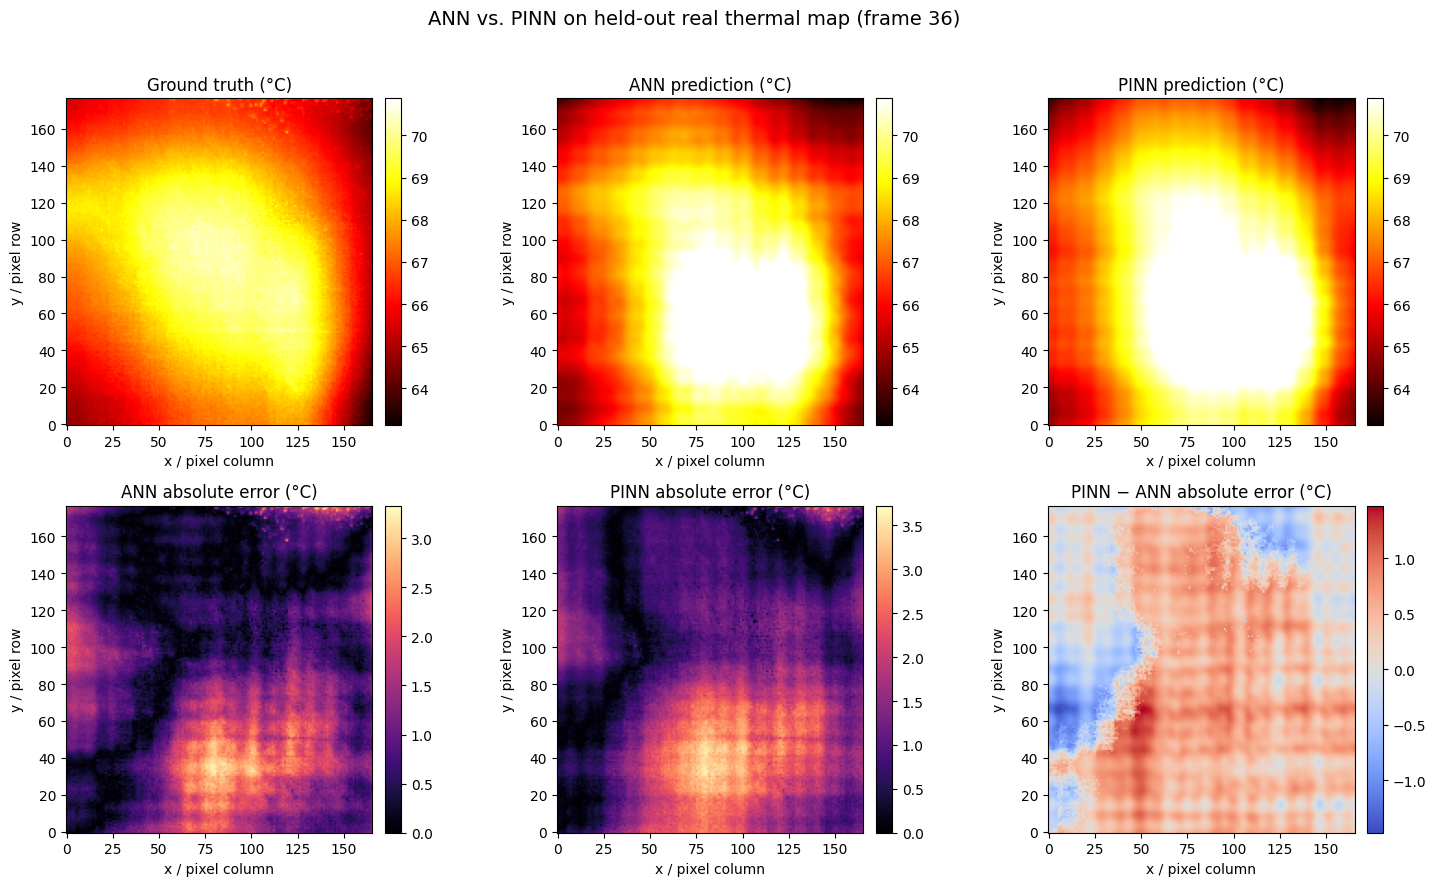

Saved: /content/drive/MyDrive/cpu_thermal_pinn_project/results_v4/figures/thermal_map_comparison.png


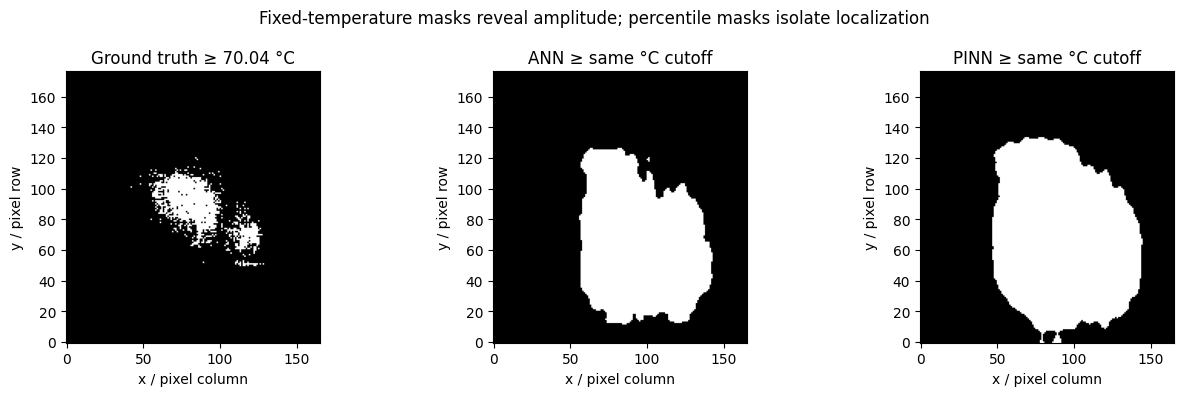

Saved: /content/drive/MyDrive/cpu_thermal_pinn_project/results_v4/figures/fixed_P95_masks.png


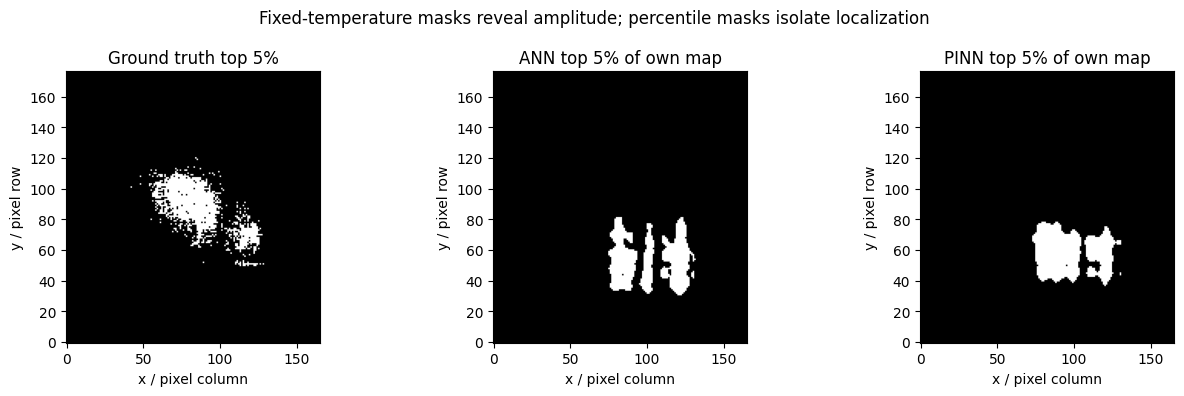

Saved: /content/drive/MyDrive/cpu_thermal_pinn_project/results_v4/figures/top5_localization_masks.png


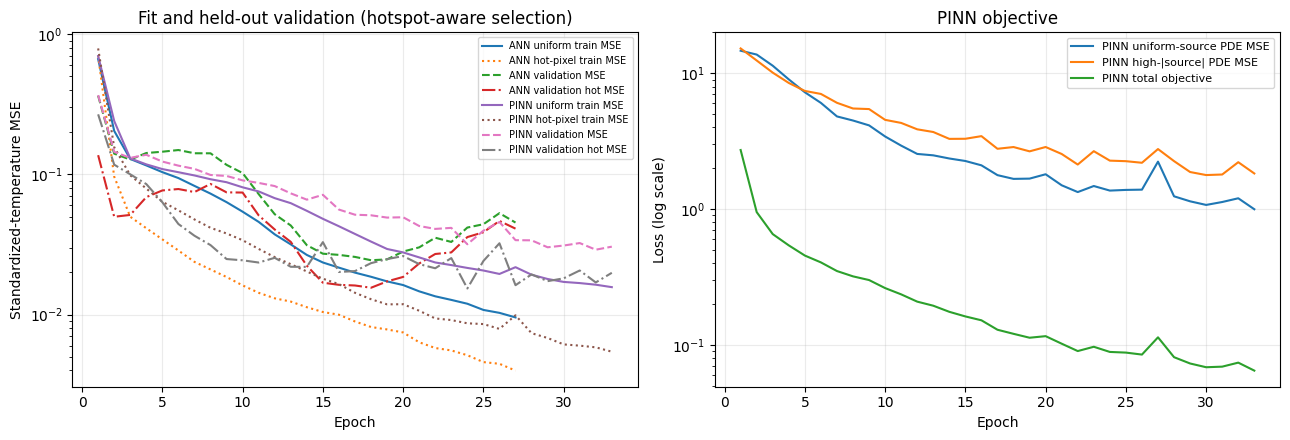

Saved: /content/drive/MyDrive/cpu_thermal_pinn_project/results_v4/figures/training_curves.png
Held-out PDE residual diagnostic:
{
  "pinn_test_pde_residual_rmse_train_source_scale_units": 5.282007694244385,
  "alpha_eff_dimensionless": 0.0001,
  "training_source_robust_center": 1.9192519187927246,
  "training_source_robust_scale": 1.6713056564331055,
  "note": "Train source targets were used in fitting only at train-frame collocation points. The held-out source used for this diagnostic is derived from test outputs after training; physical timestamps/material calibration/source measurements are not supplied."
}
Saved evaluation artifacts to: /content/drive/MyDrive/cpu_thermal_pinn_project/results_v4/metrics


In [ ]:
# 6. Evaluate uniform held-out pixels and full held-out maps; save honest hotspot diagnostics

def predict_standardized(model, inputs_np, batch_size=4096):
    model.eval(); parts=[]
    with torch.no_grad():
        for start in range(0, len(inputs_np), batch_size):
            batch=torch.from_numpy(inputs_np[start:start+batch_size]).to(DEVICE)
            parts.append(model(batch).detach().cpu().numpy().reshape(-1))
    return np.concatenate(parts) if parts else np.empty(0, dtype=np.float32)

def regression_metrics(y_true, y_pred):
    y_true=np.asarray(y_true,dtype=np.float64).reshape(-1); y_pred=np.asarray(y_pred,dtype=np.float64).reshape(-1)
    valid=np.isfinite(y_true)&np.isfinite(y_pred); y_true=y_true[valid]; y_pred=y_pred[valid]
    if len(y_true)==0: return {'MAE_C':np.nan,'RMSE_C':np.nan,'MaxAbsError_C':np.nan,'R2':np.nan}
    err=y_pred-y_true; sst=np.sum((y_true-y_true.mean())**2)
    return {'MAE_C':float(np.mean(np.abs(err))), 'RMSE_C':float(np.sqrt(np.mean(err**2))),
            'MaxAbsError_C':float(np.max(np.abs(err))), 'R2':float(1-np.sum(err**2)/sst) if sst>1e-12 else np.nan}

ann_test_c = predict_standardized(ann_model, test_X)*TEMP_STD + TEMP_MEAN
pinn_test_c = predict_standardized(pinn_model, test_X)*TEMP_STD + TEMP_MEAN
test_true_c = test_y.reshape(-1)*TEMP_STD + TEMP_MEAN
baseline_test_c = np.full_like(test_true_c, TEMP_MEAN, dtype=np.float32)
point_rows=[{'Model':'Train-mean baseline', **regression_metrics(test_true_c,baseline_test_c)}]
for name, pred in [('ANN',ann_test_c),('PINN',pinn_test_c)]:
    point_rows.append({'Model':name, **regression_metrics(test_true_c,pred)})
point_metrics_df=pd.DataFrame(point_rows)
point_metrics_df.to_csv(METRICS_DIR/'heldout_point_metrics.csv',index=False)
print('Held-out uniformly sampled pixel metrics (restored to °C):')
display(point_metrics_df.round(4))

# Build inputs for every pixel of one complete map.
x_grid,y_grid=np.meshgrid(np.linspace(0,1,WIDTH,dtype=np.float32),np.linspace(0,1,HEIGHT,dtype=np.float32))
rows_grid,cols_grid=np.indices((HEIGHT,WIDTH))
def frame_model_inputs(frame_index):
    f=np.full(HEIGHT*WIDTH,int(frame_index),dtype=np.int64)
    return make_model_inputs(f,rows_grid.reshape(-1),cols_grid.reshape(-1))

def map_hotspot_metrics(ground_truth, prediction):
    valid=np.isfinite(ground_truth)&np.isfinite(prediction)
    gt=ground_truth[valid]; pred=prediction[valid]
    base=regression_metrics(gt,pred)
    threshold=float(np.nanpercentile(ground_truth,95))
    gt_fixed=np.isfinite(ground_truth)&(ground_truth>=threshold)
    pred_fixed=np.isfinite(prediction)&(prediction>=threshold)
    inter=int(np.logical_and(gt_fixed,pred_fixed).sum()); union=int(np.logical_or(gt_fixed,pred_fixed).sum())
    precision=inter/max(int(pred_fixed.sum()),1); recall=inter/max(int(gt_fixed.sum()),1)
    fixed_iou=inter/max(union,1)
    gt_top=np.isfinite(ground_truth)&(ground_truth>=np.nanpercentile(ground_truth,95))
    pred_top=np.isfinite(prediction)&(prediction>=np.nanpercentile(prediction,95))
    top_inter=int(np.logical_and(gt_top,pred_top).sum()); top_union=int(np.logical_or(gt_top,pred_top).sum())
    gt_peak=np.unravel_index(np.nanargmax(ground_truth),ground_truth.shape)
    pred_peak=np.unravel_index(np.nanargmax(prediction),prediction.shape)
    pixloc=float(np.linalg.norm(np.asarray(gt_peak,dtype=float)-np.asarray(pred_peak,dtype=float)))
    base.update({'GT_P95_threshold_C':threshold,'PredictedHotFraction_at_GT_P95':float(pred_fixed.mean()),
                 'HotspotPrecision_at_GT_P95':float(precision),'HotspotRecall_at_GT_P95':float(recall),
                 'HotspotIoU_at_GT_P95':float(fixed_iou),'Top5PercentHotspotIoU':float(top_inter/max(top_union,1)),
                 'PeakTemperatureError_C':float(abs(np.nanmax(ground_truth)-np.nanmax(prediction))),
                 'PeakLocationError_pixels':pixloc})
    return base

# Score several full unseen maps, not just one selected picture.
rng_map=np.random.default_rng(SEED+5)
if len(test_frame_ids)>MAX_TEST_MAPS:
    eval_frame_ids=np.sort(rng_map.choice(test_frame_ids,size=MAX_TEST_MAPS,replace=False))
else:
    eval_frame_ids=np.asarray(test_frame_ids)
per_map_rows=[]
all_map_predictions={}
for fi in eval_frame_ids:
    map_inputs=frame_model_inputs(int(fi))
    ann_map=(predict_standardized(ann_model,map_inputs).reshape(HEIGHT,WIDTH)*TEMP_STD+TEMP_MEAN)
    pinn_map=(predict_standardized(pinn_model,map_inputs).reshape(HEIGHT,WIDTH)*TEMP_STD+TEMP_MEAN)
    gt_map=raw_maps[int(fi)].astype(np.float32)
    all_map_predictions[int(fi)]={'ground_truth_c':gt_map,'ann_prediction_c':ann_map,'pinn_prediction_c':pinn_map}
    baseline_map = np.full_like(gt_map, TEMP_MEAN, dtype=np.float32)
    for name,pred_map in [('Train-mean baseline',baseline_map),('ANN',ann_map),('PINN',pinn_map)]:
        per_map_rows.append({'Model':name,'FrameIndex':int(fi),**map_hotspot_metrics(gt_map,pred_map)})
per_map_df=pd.DataFrame(per_map_rows)
per_map_df.to_csv(METRICS_DIR/'per_test_map_metrics.csv',index=False)
metric_cols=[c for c in per_map_df.columns if c not in ['Model','FrameIndex']]
summary_by_model=per_map_df.groupby('Model')[metric_cols].agg(['mean','std']).round(4)
print(f'Full-map scores across {len(eval_frame_ids)} held-out maps (mean and standard deviation):')
display(summary_by_model)

# Select a deterministic held-out map solely for visualization (not for model selection).
test_frame_index=int(eval_frame_ids[len(eval_frame_ids)//2])
ground_truth_map_c=all_map_predictions[test_frame_index]['ground_truth_c']
ann_map_c=all_map_predictions[test_frame_index]['ann_prediction_c']
pinn_map_c=all_map_predictions[test_frame_index]['pinn_prediction_c']
map_rows=[]
for name,pred_map in [('ANN',ann_map_c),('PINN',pinn_map_c)]:
    map_rows.append({'Model':name,'TestFrameIndex':test_frame_index,**map_hotspot_metrics(ground_truth_map_c,pred_map)})
map_metrics_df=pd.DataFrame(map_rows)
map_metrics_df.to_csv(METRICS_DIR/'representative_map_metrics.csv',index=False)
print(f'Representative held-out frame: {test_frame_index}; fixed hotspot cutoff = {np.nanpercentile(ground_truth_map_c,95):.3f} °C')
display(map_metrics_df.round(4))

truth_finite=ground_truth_map_c[np.isfinite(ground_truth_map_c)]
color_min=float(np.nanmin(truth_finite)); color_max=float(np.nanmax(truth_finite))
if color_max<=color_min: color_max=color_min+1.0
ann_abs_error=np.abs(ann_map_c-ground_truth_map_c)
pinn_abs_error=np.abs(pinn_map_c-ground_truth_map_c)
err_difference=pinn_abs_error-ann_abs_error
fig,axes=plt.subplots(2,3,figsize=(15,9))
first_panels=[(ground_truth_map_c,'Ground truth (°C)','hot',color_min,color_max),
              (ann_map_c,'ANN prediction (°C)','hot',color_min,color_max),
              (pinn_map_c,'PINN prediction (°C)','hot',color_min,color_max)]
for ax,(arr,title,cmap,vmin,vmax) in zip(axes[0],first_panels):
    im=ax.imshow(arr,origin='lower',cmap=cmap,vmin=vmin,vmax=vmax); ax.set_title(title); ax.set_xlabel('x / pixel column'); ax.set_ylabel('y / pixel row'); fig.colorbar(im,ax=ax,fraction=.046,pad=.03)
second_panels=[(ann_abs_error,'ANN absolute error (°C)','magma',0,None),
               (pinn_abs_error,'PINN absolute error (°C)','magma',0,None),
               (err_difference,'PINN − ANN absolute error (°C)','coolwarm',None,None)]
for ax,(arr,title,cmap,vmin,vmax) in zip(axes[1],second_panels):
    im=ax.imshow(arr,origin='lower',cmap=cmap,vmin=vmin,vmax=vmax); ax.set_title(title); ax.set_xlabel('x / pixel column'); ax.set_ylabel('y / pixel row'); fig.colorbar(im,ax=ax,fraction=.046,pad=.03)
fig.suptitle(f'ANN vs. PINN on held-out real thermal map (frame {test_frame_index})',fontsize=14)
fig.tight_layout(rect=[0,0,1,.96]); map_figure_path=FIGURES_DIR/'thermal_map_comparison.png'; fig.savefig(map_figure_path,dpi=180,bbox_inches='tight'); plt.show()
print('Saved:',map_figure_path)

# Fixed absolute P95 masks intentionally show amplitude underprediction; top-5% masks show localization separately.
fixed_cutoff=float(np.nanpercentile(ground_truth_map_c,95))
fixed_masks=[np.isfinite(ground_truth_map_c)&(ground_truth_map_c>=fixed_cutoff),
             np.isfinite(ann_map_c)&(ann_map_c>=fixed_cutoff),
             np.isfinite(pinn_map_c)&(pinn_map_c>=fixed_cutoff)]
top_masks=[np.isfinite(ground_truth_map_c)&(ground_truth_map_c>=np.nanpercentile(ground_truth_map_c,95)),
           np.isfinite(ann_map_c)&(ann_map_c>=np.nanpercentile(ann_map_c,95)),
           np.isfinite(pinn_map_c)&(pinn_map_c>=np.nanpercentile(pinn_map_c,95))]
for tag,masks,titles in [
    ('fixed_P95_masks',fixed_masks,[f'Ground truth ≥ {fixed_cutoff:.2f} °C','ANN ≥ same °C cutoff','PINN ≥ same °C cutoff']),
    ('top5_localization_masks',top_masks,['Ground truth top 5%','ANN top 5% of own map','PINN top 5% of own map'])]:
    fig,axes=plt.subplots(1,3,figsize=(13,4))
    for ax,mask,title in zip(axes,masks,titles):
        im=ax.imshow(mask.astype(np.float32),origin='lower',cmap='gray',vmin=0,vmax=1)
        ax.set_title(title); ax.set_xlabel('x / pixel column'); ax.set_ylabel('y / pixel row')
    fig.suptitle('Fixed-temperature masks reveal amplitude; percentile masks isolate localization',fontsize=12)
    fig.tight_layout(); path=FIGURES_DIR/f'{tag}.png'; fig.savefig(path,dpi=180,bbox_inches='tight'); plt.show(); print('Saved:',path)

# Histories: keep supervised MSE and PDE residual on separate panels because they have different meanings/scales.
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for name,hist in [('ANN',ann_history),('PINN',pinn_history)]:
    if hist['epoch']:
        axes[0].plot(hist['epoch'],np.maximum(hist['train_uniform_mse'],1e-12),label=f'{name} uniform train MSE')
        axes[0].plot(hist['epoch'],np.maximum(hist['train_hot_mse'],1e-12),':',label=f'{name} hot-pixel train MSE')
        axes[0].plot(hist['epoch'],np.maximum(hist['val_mse'],1e-12),'--',label=f'{name} validation MSE')
        axes[0].plot(hist['epoch'],np.maximum(hist['val_hot_mse'],1e-12),'-.',label=f'{name} validation hot MSE')
axes[0].set_yscale('log'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Standardized-temperature MSE'); axes[0].set_title('Fit and held-out validation (hotspot-aware selection)'); axes[0].grid(True,alpha=.25); axes[0].legend(fontsize=7)
if pinn_history['epoch']:
    axes[1].plot(pinn_history['epoch'],np.maximum(pinn_history['pde_uniform_mse'],1e-12),label='PINN uniform-source PDE MSE')
    axes[1].plot(pinn_history['epoch'],np.maximum(pinn_history['pde_tail_mse'],1e-12),label='PINN high-|source| PDE MSE')
    axes[1].plot(pinn_history['epoch'],np.maximum(pinn_history['total_loss'],1e-12),label='PINN total objective')
axes[1].set_yscale('log'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss (log scale)'); axes[1].set_title('PINN objective'); axes[1].grid(True,alpha=.25); axes[1].legend(fontsize=8)
fig.tight_layout(); curves_path=FIGURES_DIR/'training_curves.png'; fig.savefig(curves_path,dpi=180,bbox_inches='tight'); plt.show(); print('Saved:',curves_path)

# Post-training PDE diagnostic: derive the effective source from held-out frames ONLY for evaluation,
# never fitting. This tests whether PINN predictions are consistent with the held-out map evolution.
test_source_map, test_source_frame_ids = estimate_heat_source_map(test_frame_ids)
if len(test_source_frame_ids) >= 1:
    diag_count=min(1024,MAX_TEST_POINTS)
    diag_X,diag_q,diag_f,diag_r,diag_c=sample_map_points(test_source_map,test_source_frame_ids,diag_count,SEED+777,standardize_temp=False)
    test_neighbor_lookup=build_neighbor_lookup(test_frame_ids)
    _,diag_prev_X,diag_next_X,diag_h1,diag_h2=neighbor_conditioned_inputs(diag_f,diag_r,diag_c,test_neighbor_lookup)
    diag_inputs=torch.from_numpy(diag_X).to(DEVICE)
    diag_prev=torch.from_numpy(diag_prev_X).to(DEVICE); diag_next=torch.from_numpy(diag_next_X).to(DEVICE)
    diag_q_t=torch.from_numpy(diag_q.astype(np.float32)).to(DEVICE)
    pinn_model.eval()
    with torch.enable_grad():
        residual_test=heat_residual_from_field(pinn_model,diag_inputs,diag_prev,diag_next,diag_h1,diag_h2,diag_q_t)
    test_pde_rmse=float(torch.sqrt(torch.mean((residual_test.detach()/Q_SCALE)**2)).cpu())
else:
    test_pde_rmse=None
pde_diagnostic={'pinn_test_pde_residual_rmse_train_source_scale_units':test_pde_rmse,
                'alpha_eff_dimensionless':float(ALPHA_EFF),'training_source_robust_center':Q_CENTER,
                'training_source_robust_scale':Q_SCALE,
                'note':'Train source targets were used in fitting only at train-frame collocation points. The held-out source used for this diagnostic is derived from test outputs after training; physical timestamps/material calibration/source measurements are not supplied.'}
with open(METRICS_DIR/'pde_diagnostic.json','w') as f: json.dump(pde_diagnostic,f,indent=2)
print('Held-out PDE residual diagnostic:'); print(json.dumps(pde_diagnostic,indent=2))

np.savez_compressed(PREDICTIONS_DIR/'heldout_map_predictions.npz',
    frame_index=np.array([test_frame_index]),ground_truth_c=ground_truth_map_c,
    ann_prediction_c=ann_map_c,pinn_prediction_c=pinn_map_c,
    ann_abs_error_c=ann_abs_error,pinn_abs_error_c=pinn_abs_error)
summary={'run_version':RUN_VERSION,'dataset_file':str(DATASET_PATH),'dataset_shape_N_H_W':[int(N_FRAMES),int(HEIGHT),int(WIDTH)],
         'feature_dim':FEATURE_DIM,'split_mode':SPLIT_MODE,'train_frame_count':int(len(train_frame_ids)),
         'validation_frame_count':int(len(val_frame_ids)),'test_frame_count':int(len(test_frame_ids)),
         'evaluated_full_map_frame_indices':[int(x) for x in eval_frame_ids],
         'temperature_scaler':{'mean_c':TEMP_MEAN,'std_c':TEMP_STD},
         'source_estimation':{'training_source_frames':int(len(source_frame_ids)),'q_robust_center':Q_CENTER,'q_robust_scale':Q_SCALE,'alpha_eff':ALPHA_EFF},
         'point_metrics':point_rows,'representative_map_metrics':map_rows,'pde_diagnostic':pde_diagnostic,
         'checkpoints':str(CHECKPOINTS_DIR),'figures':[str(map_figure_path),str(curves_path)]}
with open(METRICS_DIR/'run_summary.json','w') as f: json.dump(summary,f,indent=2)
print('Saved evaluation artifacts to:',METRICS_DIR)

## Verification checklist

The run is successful when:

- The analytic heat-equation derivative check prints `PASS` with residual below `1e-8`.
- The dataset filename/shape printout is correct and train/validation/test **frame indices are disjoint**.
- Logs show both the ANN and PINN using the same initial weights/batch order, and only the PINN has a nonzero PDE objective.
- `heldout_point_metrics.csv` and `per_test_map_metrics.csv` contain **Train-mean baseline, ANN, and PINN** rows with finite metrics.
- The actual held-out map, absolute-error plots, fixed-P95 masks, top-5% localization masks and training curves are saved under `MyDrive/cpu_thermal_pinn_project/results_v4/`.
- `ann_best.pt`, `pinn_best.pt`, `ann_latest.pt` and `pinn_latest.pt` exist in Drive.

**Interpreting hotspots:** a black panel in `fixed_P95_masks.png` means the model failed to predict temperatures above the ground-truth P95 cutoff. `top5_localization_masks.png` measures location independently of amplitude and does not replace the fixed-threshold metrics.

## Recovery after Colab disconnect

1. Reopen the saved notebook, then rerun setup, data loading, splitting, source-map creation and model-definition cells.
2. Run the training cell; matching `ann_latest.pt` / `pinn_latest.pt` checkpoints resume. A changed experiment signature intentionally starts a fresh v4 run.
3. Run evaluation again to recreate metrics, figures and the results ZIP.

Keep the dataset, seed, split, alpha, architecture and point budgets unchanged when resuming. `FORCE_RETRAIN = False` is the normal setting. Set it to `True` only when intentionally restarting from scratch; if that run is interrupted, set it back to `False` before rerunning so saved checkpoints are used. Results are in `results_v4` so earlier v1/v2/v3 outputs remain untouched.

### Scientific limitation

The dataset does not contain all physical timestamps, material coefficients, dimensions, boundary conditions, or measured heat-source maps. The effective source is computed from training maps and `ALPHA_EFF` is dimensionless. This keeps the heat-equation residual internally consistent but is not a fully calibrated chip simulator. A PINN is not guaranteed to beat the ANN on held-out error; report the measured scores rather than assuming a win.

In [ ]:
# 7. Build a persistent results bundle (optional browser download)
ARCHIVE_BASE=PROJECT_DIR/'cpu_thermal_pinn_results_v4'
archive_path=shutil.make_archive(str(ARCHIVE_BASE),'zip',root_dir=str(RESULTS_DIR))
print('Results archive created:',archive_path)
print('Persistent project directory:',PROJECT_DIR)
for path in sorted(RESULTS_DIR.rglob('*')):
    if path.is_file(): print(f'  {path.relative_to(PROJECT_DIR)} ({path.stat().st_size/1024:.1f} KiB)')
DOWNLOAD_RESULTS_ZIP=False
if DOWNLOAD_RESULTS_ZIP:
    from google.colab import files
    files.download(archive_path)

Results archive created: /content/drive/MyDrive/cpu_thermal_pinn_project/cpu_thermal_pinn_results_v4.zip
Persistent project directory: /content/drive/MyDrive/cpu_thermal_pinn_project
  results_v4/checkpoints/ann_best.pt (154.4 KiB)
  results_v4/checkpoints/ann_latest.pt (612.3 KiB)
  results_v4/checkpoints/pinn_best.pt (154.5 KiB)
  results_v4/checkpoints/pinn_latest.pt (612.8 KiB)
  results_v4/figures/fixed_P95_masks.png (111.9 KiB)
  results_v4/figures/thermal_map_comparison.png (536.1 KiB)
  results_v4/figures/top5_localization_masks.png (108.4 KiB)
  results_v4/figures/training_curves.png (236.1 KiB)
  results_v4/metrics/ann_history.json (5.1 KiB)
  results_v4/metrics/heldout_point_metrics.csv (0.3 KiB)
  results_v4/metrics/pde_diagnostic.json (0.5 KiB)
  results_v4/metrics/per_test_map_metrics.csv (7.5 KiB)
  results_v4/metrics/pinn_history.json (7.6 KiB)
  results_v4/metrics/representative_map_metrics.csv (0.7 KiB)
  results_v4/metrics/run_summary.json (3.4 KiB)
  results_v4/pred